In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

In [2]:
df = pd.read_csv("cars.csv")

df.head()

,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
0,mazda,2,5500,2008,with mileage,162000.0,petrol,1500.0,burgundy,mechanics,front-wheel drive,B
1,mazda,2,5350,2009,with mileage,120000.0,petrol,1300.0,black,mechanics,front-wheel drive,B
2,mazda,2,7000,2009,with mileage,61000.0,petrol,1500.0,silver,auto,front-wheel drive,B
3,mazda,2,3300,2003,with mileage,265000.0,diesel,1400.0,white,mechanics,front-wheel drive,B
4,mazda,2,5200,2008,with mileage,97183.0,diesel,1400.0,gray,mechanics,front-wheel drive,B


In [3]:
print(df.shape)

print(df.info())

print(df.isnull().sum())

(56244, 12)
<class 'pandas.DataFrame'>
RangeIndex: 56244 entries, 0 to 56243
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make                 56244 non-null  str    
 1   model                56244 non-null  str    
 2   priceUSD             56244 non-null  int64  
 3   year                 56244 non-null  int64  
 4   condition            56244 non-null  str    
 5   mileage(kilometers)  56244 non-null  float64
 6   fuel_type            56244 non-null  str    
 7   volume(cm3)          56197 non-null  float64
 8   color                56244 non-null  str    
 9   transmission         56244 non-null  str    
 10  drive_unit           54339 non-null  str    
 11  segment              50953 non-null  str    
dtypes: float64(2), int64(2), str(8)
memory usage: 5.1 MB
None
make                      0
model                     0
priceUSD                  0
year                      0
condition      

In [4]:
df.describe()

,priceUSD,year,mileage(kilometers),volume(cm3)
count,56244.000000,56244.000000,5.624400e+04,56197.000000
mean,7415.456440,2003.454840,2.443956e+05,2104.860615
std,8316.959261,8.144247,3.210307e+05,959.201633
min,48.000000,1910.000000,0.000000e+00,500.000000
25%,2350.000000,1998.000000,1.370000e+05,1600.000000
50%,5350.000000,2004.000000,2.285000e+05,1996.000000
75%,9807.500000,2010.000000,3.100000e+05,2300.000000
max,235235.000000,2019.000000,9.999999e+06,20000.000000


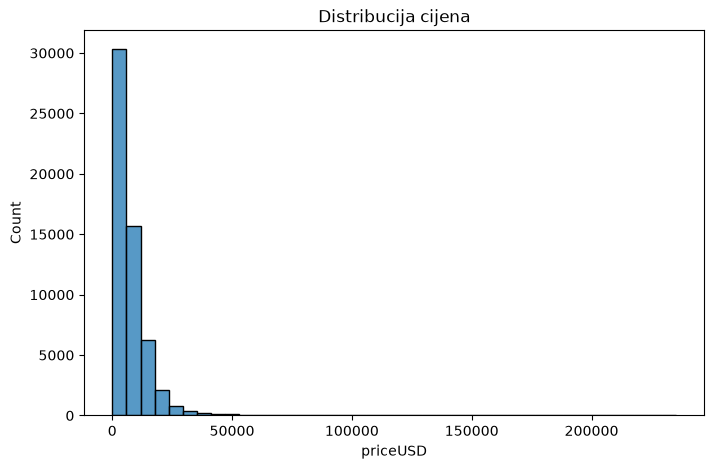

In [5]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["priceUSD"],
    bins=40
)

plt.title("Distribucija cijena")

plt.show()

In [6]:
current_year = 2025

df["car_age"] = (
    current_year -
    df["year"]
)

df["engine_volume_liters"] = (
    df["volume(cm3)"] / 1000
)

df["mileage_per_year"] = (
    df["mileage(kilometers)"] /
    (df["car_age"] + 1)
)

In [7]:
X = df.drop(
    columns=["priceUSD"]
)

y = df["priceUSD"]

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [9]:
numerical_features = [
    "year",
    "mileage(kilometers)",
    "volume(cm3)",
    "car_age",
    "engine_volume_liters",
    "mileage_per_year"
]

categorical_features = [
    "make",
    "model",
    "condition",
    "fuel_type",
    "color",
    "transmission",
    "drive_unit",
    "segment"
]

In [10]:
numeric_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),

    (
        "scaler",
        StandardScaler()
    )
])

categorical_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent"
        )
    ),

    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),

        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [14]:
models = {
    "Linear Regression":
        LinearRegression(),

    "Decision Tree":
        DecisionTreeRegressor(
            random_state=42,
            max_depth=10
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=20,
            max_depth=10,
            random_state=42,
            n_jobs=-1
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=50,
            random_state=42
        )
}

In [15]:
results = []

In [16]:
for name, model in models.items():

    pipe = Pipeline([
        (
            "preprocessor",
            preprocessor
        ),

        (
            "model",
            model
        )
    ])

    pipe.fit(
        X_train,
        y_train
    )

    predictions = pipe.predict(
        X_test
    )

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    mse = mean_squared_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test,
        predictions
    )

    results.append([
        name,
        mae,
        rmse,
        r2
    ])

    print("\n", name)

    print("MAE:", mae)

    print("RMSE:", rmse)

    print("R2:", r2)


 Linear Regression
MAE: 2088.43054165556
RMSE: 4417.582779510229
R2: 0.7023652959465954

 Decision Tree
MAE: 1529.6228310950312
RMSE: 3444.2397839865057
R2: 0.8190740200910634

 Random Forest
MAE: 1389.702767185635
RMSE: 2970.689138592026
R2: 0.8654051036444923

 Gradient Boosting
MAE: 1690.584712674878
RMSE: 3350.937280656967
R2: 0.8287436143129112


## Izbor finalnog modela

Na osnovu rezultata poređenja svih modela, Random Forest Regressor je ostvario najbolje performanse.

Model ima najmanji MAE i RMSE, kao i najveću vrijednost R², što znači da najtačnije procjenjuje cijene automobila na testnom skupu podataka.

Zbog toga je Random Forest izabran kao finalni model za ovaj projekat.

In [17]:
final_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),

    (
        "model",
        RandomForestRegressor(
            n_estimators=20,
            max_depth=10,
            random_state=42,
            n_jobs=-1
        )
    )
])

final_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['make','model','year',...,'car_age','engine_volume_liters', 'mileage_per_year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset o

In [18]:
import joblib

joblib.dump(
    final_model,
    "car_price_model.joblib"
)

print(
    "Model uspješno sačuvan."
)

Model uspješno sačuvan.


In [19]:
predictions = final_model.predict(X_test)

comparison = pd.DataFrame({
    "Stvarna cijena": y_test.values,
    "Predviđena cijena": predictions
})

comparison["Greška"] = (
    abs(
        comparison["Stvarna cijena"] -
        comparison["Predviđena cijena"]
    )
)

comparison.head(10)

,Stvarna cijena,Predviđena cijena,Greška
0,2050,2715.528101,665.528101
1,4500,4416.260559,83.739441
2,3500,3609.761659,109.761659
3,21000,15614.884022,5385.115978
4,3990,3097.111271,892.888729
5,1450,1176.970610,273.029390
6,2450,2353.305961,96.694039
7,2000,1176.970610,823.029390
8,2400,2415.281745,15.281745
9,8000,6561.886747,1438.113253


# Zaključak

U ovom projektu razvijen je model mašinskog učenja za procjenu cijene polovnih automobila na osnovu njihovih karakteristika.

Nakon analize i čišćenja podataka kreirane su dodatne karakteristike kao što su starost vozila, kilometraža po godini starosti i zapremina motora izražena u litrima. Podaci su zatim pripremljeni korištenjem imputacije, skaliranja numeričkih atributa i One-Hot kodiranja kategorijskih vrijednosti.

Testirana su četiri regresiona modela: Linear Regression, Decision Tree Regressor, Random Forest Regressor i Gradient Boosting Regressor.

Najbolje rezultate ostvario je Random Forest Regressor sa sljedećim metrikama:

- MAE: 1389.70
- RMSE: 2970.69
- R²: 0.865

To znači da model u prosjeku griješi oko 1390 dolara prilikom procjene cijene vozila i uspješno objašnjava približno 86.5% varijacije cijena u skupu podataka.

Na osnovu svih evaluacionih metrika Random Forest Regressor izabran je kao konačno rješenje i sačuvan za dalju upotrebu.
